In [1]:
# Cell 1 - Setup: imports and paths
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether the notebook runs from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LOG = ROOT / "data/raw/HDFS_v1/HDFS.log"
LABELS = ROOT / "data/raw/HDFS_v1/preprocessed/anomaly_label.csv"
FIG_DIR = ROOT / "reports/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
print("Log exists:", LOG.exists(), "| Labels exist:", LABELS.exists())

Log exists: True | Labels exist: True


In [2]:
# Cell 2 - Stream the raw log once and aggregate per block / component / minute
import time

LINE_RE = re.compile(r"^(\d{6}) (\d{6}) (\d+) (\w+) ([^:]+): (.*)$")
BLOCK_RE = re.compile(r"blk_-?\d+")

lines_per_block, warn_per_block = Counter(), Counter()
first_seen, last_seen = {}, {}
components, per_minute = Counter(), Counter()

start = time.perf_counter()
with LOG.open(encoding="utf-8", errors="replace") as f:
    for line in f:
        m = LINE_RE.match(line)
        if m is None:
            continue
        date, time_, _pid, level, comp, content = m.groups()
        ts = date + time_
        components[comp] += 1
        per_minute[date + time_[:4]] += 1          # yyMMddHHmm
        for blk in set(BLOCK_RE.findall(content)):
            lines_per_block[blk] += 1
            if level == "WARN":
                warn_per_block[blk] += 1
            first_seen.setdefault(blk, ts)
            last_seen[blk] = ts

print(f"Done in {time.perf_counter() - start:.1f}s | blocks: {len(lines_per_block):,} "
      f"| components: {len(components)} | minutes: {len(per_minute):,}")

Done in 24.5s | blocks: 575,061 | components: 9 | minutes: 2,322


In [3]:
# Cell 3 - Per-block DataFrame joined with labels
labels = pd.read_csv(LABELS)

blocks = pd.DataFrame({
    "BlockId": list(lines_per_block.keys()),
    "n_lines": list(lines_per_block.values()),
})
blocks["n_warn"] = blocks["BlockId"].map(warn_per_block).fillna(0).astype(int)
first = pd.to_datetime(blocks["BlockId"].map(first_seen), format="%y%m%d%H%M%S")
last = pd.to_datetime(blocks["BlockId"].map(last_seen), format="%y%m%d%H%M%S")
blocks["duration_s"] = (last - first).dt.total_seconds()
blocks["has_warn"] = blocks["n_warn"] > 0

blocks = blocks.merge(labels, on="BlockId", how="left")
print("Unlabelled blocks:", blocks["Label"].isna().sum())

summary = blocks.groupby("Label")[["n_lines", "n_warn", "duration_s"]].describe(
    percentiles=[0.5, 0.95]).T
display(summary.round(1))
display(pd.crosstab(blocks["Label"], blocks["has_warn"], normalize="index").round(3))

Unlabelled blocks: 0


Label             Anomaly    Normal
n_lines    count  16838.0  558223.0
           mean      17.1      19.5
           std       12.4       4.8
           min        2.0      13.0
           50%       20.0      19.0
           95%       38.0      28.0
           max      284.0     298.0
n_warn     count  16838.0  558223.0
           mean       0.9       0.6
           std        1.4       1.6
           min        0.0       0.0
           50%        0.0       0.0
           95%        3.0       3.0
           max       17.0      41.0
duration_s count  16838.0  558223.0
           mean   14089.5   16870.9
           std    18376.6   17865.7
           min        0.0       0.0
           50%     4920.5    7303.0
           95%    51205.2   50800.9
           max    53924.0   54025.0

has_warn,False,True
Label,,
Anomaly,0.518,0.482
Normal,0.774,0.226


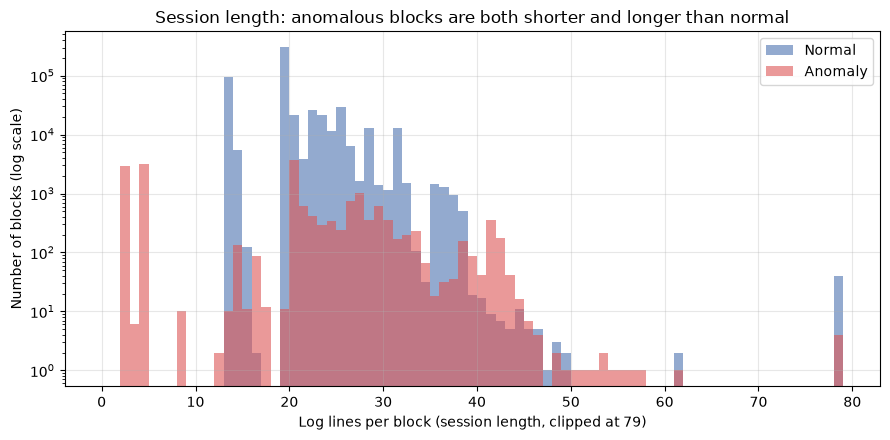

In [4]:
# Cell 4 - Session length distribution by class
fig, ax = plt.subplots()
bins = np.arange(0, 80, 1)
for label, color in [("Normal", "#4C72B0"), ("Anomaly", "#DD5555")]:
    ax.hist(blocks.loc[blocks["Label"] == label, "n_lines"].clip(upper=79),
            bins=bins, alpha=0.6, label=label, color=color)
ax.set_yscale("log")
ax.set_xlabel("Log lines per block (session length, clipped at 79)")
ax.set_ylabel("Number of blocks (log scale)")
ax.set_title("Session length: anomalous blocks are both shorter and longer than normal")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_session_length_by_label.png", dpi=150)
plt.show()

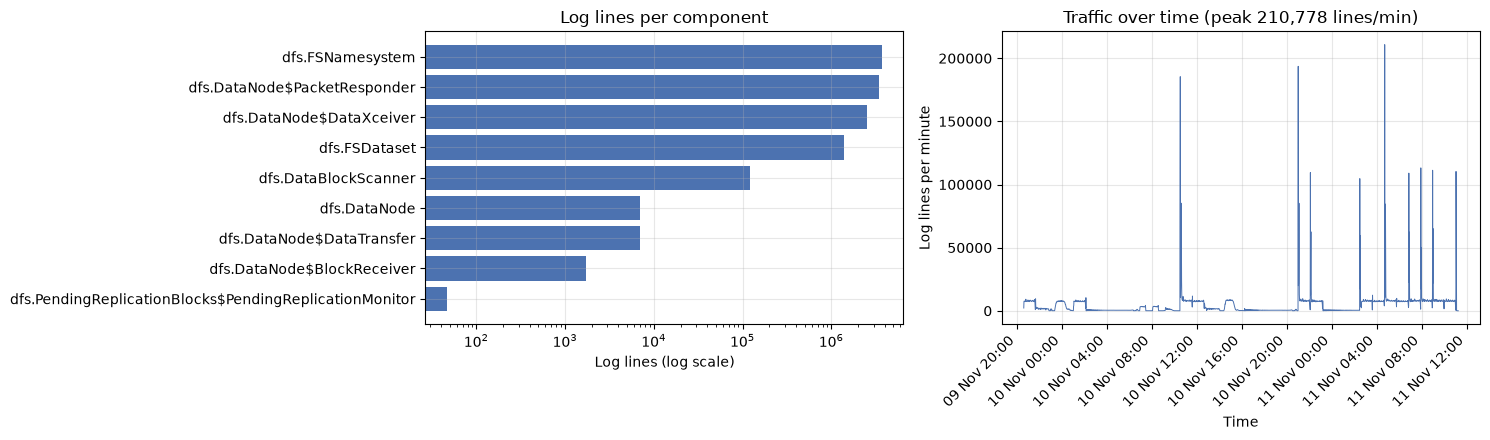

dfs.FSNamesystem                                          3700245
dfs.DataNode$PacketResponder                              3413350
dfs.DataNode$DataXceiver                                  2518678
dfs.FSDataset                                             1407597
dfs.DataBlockScanner                                       120046
dfs.DataNode                                                 7002
dfs.DataNode$DataTransfer                                    6946
dfs.DataNode$BlockReceiver                                   1718
dfs.PendingReplicationBlocks$PendingReplicationMonitor         47

Lines/min - mean: 4,813 | p95: 8,595 | peak: 210,778 (= 3,513 lines/sec)


In [6]:
# Cell 5 - Component distribution and traffic over time
import matplotlib.dates as mdates

comp_df = pd.Series(components).sort_values()
traffic = pd.Series(per_minute)
traffic.index = pd.to_datetime(traffic.index, format="%y%m%d%H%M")
traffic = traffic.sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

ax1.barh(comp_df.index, comp_df.values, color="#4C72B0")
ax1.set_xscale("log")
ax1.set_xlabel("Log lines (log scale)")
ax1.set_title("Log lines per component")

ax2.plot(traffic.index, traffic.values, linewidth=0.7, color="#4C72B0")
ax2.set_xlabel("Time")
ax2.set_ylabel("Log lines per minute")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
ax2.xaxis.set_major_locator(mdates.HourLocator(interval=4))
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
ax2.set_title(f"Traffic over time (peak {traffic.max():,} lines/min)")

fig.tight_layout()
fig.savefig(FIG_DIR / "02_components_and_traffic.png", dpi=150)
plt.show()

print(comp_df.sort_values(ascending=False).to_string())
print(f"\nLines/min - mean: {traffic.mean():,.0f} | p95: {traffic.quantile(0.95):,.0f} | "
      f"peak: {traffic.max():,} (= {traffic.max() / 60:,.0f} lines/sec)")

## EDA - Key findings

1. **Data quality:** 11,175,629 lines, 0 malformed, every line has a block ID; 575,061 blocks, all labelled.
2. **Class imbalance:** 16,838 anomalous blocks (2.93%) -> use precision, recall, F1 and PR-AUC, not accuracy.
3. **Session length separates classes:** normal blocks are consistent (min 13, median 19 lines, std 4.8);
   anomalies range 2-284 lines (std 12.4). Missing or repeated events signal anomalies -> event-count vectors.
4. **WARN is not enough:** 48% of anomalies contain a WARN, but so do 22.6% of normal blocks (~126k).
   A keyword rule would miss half the anomalies and raise ~126k false alarms -> justifies template-based ML.
5. **Duration does not separate classes** -> excluded as a feature.
6. **4 components produce ~99% of lines;** rare components (DataTransfer, BlockReceiver,
   PendingReplicationMonitor) relate to failures -> keep rare templates (low `min_template_freq`).
7. **Traffic:** mean ~80 lines/s, p95 ~143 lines/s, burst peak ~3,500 lines/s -> the system must
   handle bursts; real-time throughput target is >= 3,500 lines/s.